# Redes: variables al corte y fuga de información

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Primer conteo válido de campaña:** 0
- **Grado retrospectivo inválido:** 24
- **Invariancia a eventos futuros:** True
- **AP individual temporal:** 0.3292
- **AP con red temporal:** 0.3186
- **Campañas de prueba no vistas por bloque:** True

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Cómo distinguir reutilización observada de conexiones que solo se conocen después? Construimos enlaces sintéticos reales, agregados bitemporales y un contraejemplo retrospectivo.

### Supuestos y población

Un enlace tiene application_id, entity, event_at y available_at. No se usan etiquetas de vecinos. Compartir un dispositivo puede ser legítimo; el conteo no es una probabilidad de fraude.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Construir el grafo temporal


$$N_v(t,w)=\left|\{i: v_i=v,\ t-w\le e_i<t,\ a_i\le t,\ i\ne i_{actual}\}\right|.$$

$e_i$ es fecha del hecho y $a_i$ disponibilidad. Se cuentan solicitudes distintas y se excluye la solicitud actual. Un dato tardío no pertenece al pasado disponible.

,day,entity,causal_count,invalid_retrospective_degree
55,55,campaign-device,0,24
56,56,campaign-device,1,24
57,57,campaign-device,2,24
58,58,campaign-device,3,24
59,59,campaign-device,4,24
60,60,campaign-device,5,24
61,61,campaign-device,6,24
62,62,campaign-device,7,24


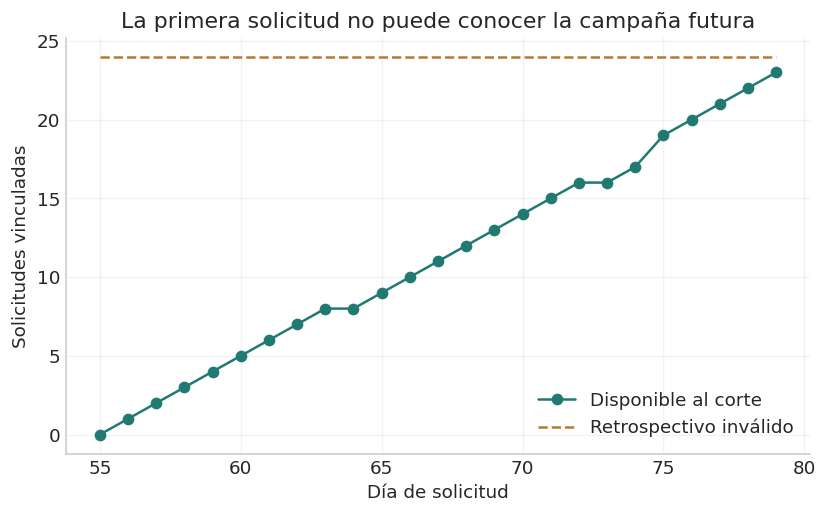

In [2]:
links=[]
for i in range(120):
    entity='campaign-device' if 55<=i<80 else ('shared-hub' if i%5==0 else f'private-{i}')
    delay=12 if i%9==0 else 0
    links.append({'application_id':f'app-{i}','entity':entity,'event_at':float(i),'available_at':float(i+delay)})
rows=[]
for link in links:
    t=link['event_at'];entity=link['entity']
    safe=shared_entity_count(links,entity,t,link['application_id'],window=30)
    # Deliberately invalid: future degree from the complete retrospective graph.
    future_degree=len({z['application_id'] for z in links if z['entity']==entity and z['application_id']!=link['application_id']})
    rows.append({'day':int(t),'entity':entity,'causal_count':safe,'invalid_retrospective_degree':future_degree})
graph_data=pd.DataFrame(rows)
display(graph_data[graph_data['entity']=='campaign-device'].head(8))
fig,ax=plt.subplots();subset=graph_data[graph_data['entity']=='campaign-device']
ax.plot(subset['day'],subset['causal_count'],label='Disponible al corte',color=TEAL,marker='o')
ax.plot(subset['day'],subset['invalid_retrospective_degree'],label='Retrospectivo inválido',color=GOLD,linestyle='--')
ax.set(xlabel='Día de solicitud',ylabel='Solicitudes vinculadas',title='La primera solicitud no puede conocer la campaña futura');ax.legend();plt.show()

La serie retrospectiva incluye hechos posteriores y una ventana distinta. Se muestra como contraejemplo inválido y nunca alimenta un resultado de desempeño. Las diferencias no prueban por sí solas qué modelo detecta mejor.

## 2. Hubs legítimos y señales insuficientes


Un grado alto puede tener varias explicaciones. Una normalización propuesta es $R_v=N_v/\log(2+D_v)$, donde $D_v$ es grado histórico disponible. Atenúa infraestructura compartida, pero también puede atenuar campañas: debe validarse, no presumirse correcta.

,solicitudes,conteo_medio,conteo_maximo
entity,,,
campaign-device,25,11.2800,23
shared-hub,19,3.5789,6


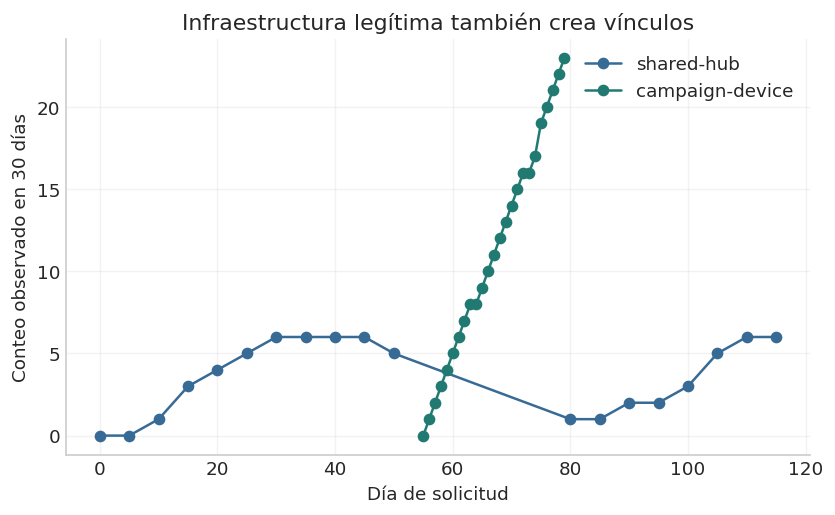

In [3]:
summary=graph_data[graph_data['entity'].isin(['shared-hub','campaign-device'])].groupby('entity').agg(solicitudes=('day','size'),conteo_medio=('causal_count','mean'),conteo_maximo=('causal_count','max'))
display(summary)
fig,ax=plt.subplots();
for entity,color in [('shared-hub',BLUE),('campaign-device',TEAL)]:
    subset=graph_data[graph_data['entity']==entity]
    ax.plot(subset['day'],subset['causal_count'],marker='o',label=entity,color=color)
ax.set(xlabel='Día de solicitud',ylabel='Conteo observado en 30 días',title='Infraestructura legítima también crea vínculos');ax.legend();plt.show()

El hub se etiqueta legítimo por construcción del ejemplo, no por inferencia del detector. Un solo conteo no distingue intención, titulares ni destino final de fondos. Se requieren fuentes y adjudicación independientes.

## 3. Eventos tardíos y deduplicación


La condición $a_i\le t$ se vuelve visible con un enlace antiguo que llega tarde. Una duplicación física de fila no debe duplicar la entidad lógica.

In [4]:
late={'application_id':'late-app','entity':'test-device','event_at':5.,'available_at':20.}
observations=[shared_entity_count([late,late],'test-device',float(t),window=30) for t in [10,19,20,21]]
display(pd.DataFrame({'corte':[10,19,20,21],'solicitudes_distintas':observations}))
future={'application_id':'future','entity':'campaign-device','event_at':200.,'available_at':200.}
before=shared_entity_count(links,'campaign-device',65.,'app-65')
after=shared_entity_count(links+[future],'campaign-device',65.,'app-65')

,corte,solicitudes_distintas
0,10,0
1,19,0
2,20,1
3,21,1


La igualdad al instante de disponibilidad está permitida; la ventana del hecho excluye la solicitud en t. No se afirma que el ejemplo implemente resolución de identidad, GNN ni separación de campañas fuera de muestra.

## Desarrollo ampliado: modelo, estimación y uso


**Uso:** buscar coordinación en solicitudes que comparten dispositivos o destinos. **Entrada:** enlaces fechados y una señal individual de contradicción. **Salida:** ranking probabilístico experimental más razones de variables. Un vínculo compartido no adjudica fraude; la infraestructura legítima se incluye como control negativo.

A continuación se ajustan dos modelos a un nuevo generador: individual y con variables de red. El target es latente en el simulador y origina señales imperfectas; no se define por cruzar un umbral del conteo. El split es temporal con maduración de etiquetas y campañas nuevas por bloque.

In [5]:
advanced_metrics = {}
advanced_rng = np.random.default_rng(9221)

### 4. Generador con infraestructura legítima y campañas nuevas


Sea $Y_i\sim Bernoulli(\pi)$; una parte de fraudes comparte dispositivo por campaña, mientras algunos legítimos usan un hub. La evidencia individual A tiene distribuciones solapadas. Se generan enlaces observables antes de adjudicar Y; las etiquetas llegan 12 días después.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
network_n=1000
network_time=np.arange(network_n)/5
network_y=advanced_rng.binomial(1,.09,network_n)
individual_signal=np.clip(advanced_rng.normal(.22+.25*network_y,.18,network_n),0,1)
network_links=[];is_hub=[]
for i in range(network_n):
    hub=bool(network_y[i]==0 and advanced_rng.random()<.18)
    campaign=bool(network_y[i]==1 and advanced_rng.random()<.75)
    entity=(f'ring-{int(network_time[i]//20)}' if campaign else ('legitimate-hub' if hub else f'private-{i}'))
    delay=2. if i%11==0 else 0.
    network_links.append({'application_id':str(i),'entity':entity,'event_at':float(network_time[i]),'available_at':float(network_time[i]+delay)})
    is_hub.append(hub)
entity_available=np.array([e['available_at']<=e['event_at'] for e in network_links])
network_count=np.array([shared_entity_count(network_links,e['entity'],e['event_at'],e['application_id'],window=20) if known else 0 for e,known in zip(network_links,entity_available)])
network_x=np.column_stack([individual_signal,np.log1p(network_count),individual_signal*np.log1p(network_count),(~entity_available).astype(float)])
network_train=(network_time<100)&(network_time+12<=120)
network_test=network_time>=140
assert network_time[network_train].max()+12<=120
assert network_time[network_test].min()>=140
print('Train:',network_train.sum(),'test:',network_test.sum(),'positivos de prueba:',network_y[network_test].sum())

Train: 500 test: 300 positivos de prueba: 21


**Interpretación y uso.** Las asignaciones de dispositivo dependen del target latente por diseño causal del generador; el constructor de variables solo ve los enlaces, no el target. Esta simulación no es evidencia de cómo opera una campaña real.

### 5. Modelo individual frente a modelo de red


El baseline usa $\operatorname{logit}(p)=\beta_0+\beta_1 A$. El challenger añade $R=\log(1+N)$ e interacción:
$$\operatorname{logit}(p)=\beta_0+\beta_1 A+\beta_2 R+\beta_3 AR+\beta_4 M.$$

La interacción permite que una discrepancia individual y reutilización tengan aporte conjunto. M indica que la entidad actual aún no estaba disponible; su conteo se codifica como cero junto a ese indicador, diferenciándolo de cero observado. Escalado y logit se ajustan solo en entrenamiento; no se seleccionan hiperparámetros mirando la prueba.

,modelo,AP,Brier
0,individual,0.3292,0.0567
1,individual + red,0.3186,0.0578


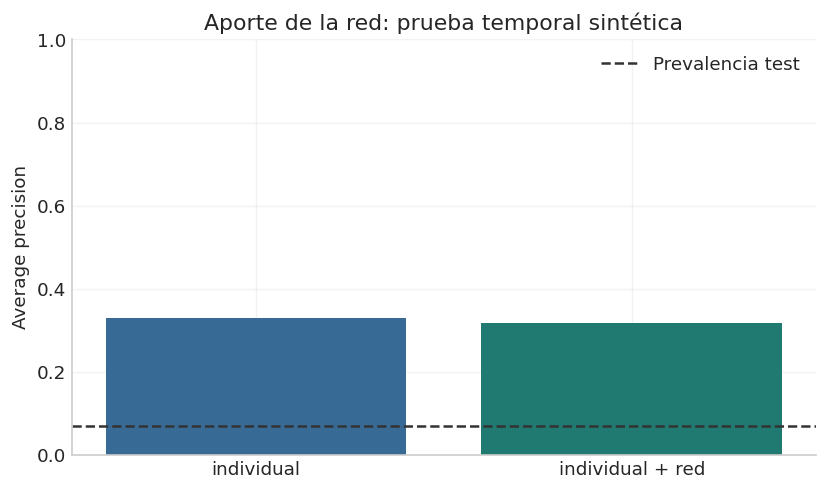

In [7]:
individual_model=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=500))
network_model=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=500))
individual_model.fit(network_x[network_train,:1],network_y[network_train])
network_model.fit(network_x[network_train],network_y[network_train])
individual_p=individual_model.predict_proba(network_x[network_test,:1])[:,1]
network_p=network_model.predict_proba(network_x[network_test])[:,1]
network_scores=pd.DataFrame([{'modelo':name,'AP':average_precision_score(network_y[network_test],p),'Brier':brier_score_loss(network_y[network_test],p)} for name,p in [('individual',individual_p),('individual + red',network_p)]])
display(network_scores)
fig,ax=plt.subplots();ax.bar(network_scores['modelo'],network_scores['AP'],color=[BLUE,TEAL])
ax.axhline(network_y[network_test].mean(),color='#333333',linestyle='--',label='Prevalencia test')
ax.set(ylim=(0,1),ylabel='Average precision',title='Aporte de la red: prueba temporal sintética');ax.legend();plt.show()

**Interpretación y uso.** AP y Brier responden a preguntas distintas. El resultado corresponde al mecanismo generado, con dispositivos nuevos por campaña en prueba; no certifica generalización a redes de personas reales ni reemplaza calibración posterior.

### 6. Falsos positivos en un hub legítimo


A igual capacidad K se revisan los primeros K scores. La precisión es $TP/K$; una tasa de derivación en legítimos requiere denominador explícito. No se usa 0,5 como umbral de aprobación.

,modelo,K,precision_K,legitimos_derivados,hubs_legitimos_revisados,hubs_disponibles
0,individual,25,0.2800,18,5,50
1,individual + red,25,0.3200,17,7,50


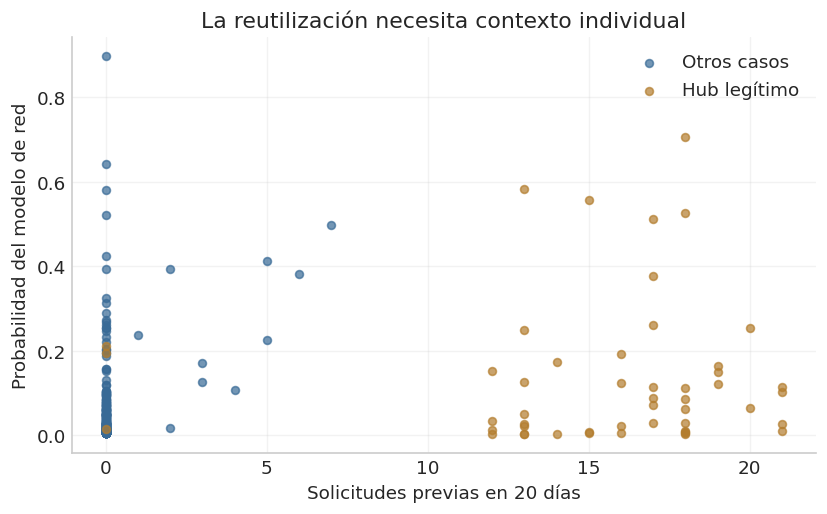

In [8]:
network_K=25
network_eval=[]
legitimate=network_y[network_test]==0
hub_mask=np.array(is_hub)[network_test]
for name,p in [('individual',individual_p),('individual + red',network_p)]:
    selected=np.zeros(len(p),bool);selected[np.argsort(-p,kind='stable')[:network_K]]=True
    network_eval.append({'modelo':name,'K':network_K,'precision_K':network_y[network_test][selected].mean(),
                         'legitimos_derivados':int((selected&legitimate).sum()),
                         'hubs_legitimos_revisados':int((selected&hub_mask).sum()),'hubs_disponibles':int(hub_mask.sum())})
display(pd.DataFrame(network_eval))
fig,ax=plt.subplots()
for flag,label,color in [(False,'Otros casos',BLUE),(True,'Hub legítimo',GOLD)]:
    mask=hub_mask==flag
    ax.scatter(network_count[network_test][mask],network_p[mask],s=22,alpha=.7,label=label,color=color)
ax.set(xlabel='Solicitudes previas en 20 días',ylabel='Probabilidad del modelo de red',title='La reutilización necesita contexto individual');ax.legend();plt.show()

**Interpretación y uso.** La tabla muestra si un hub consume la cola aunque sea legítimo. Si la variable de red solo penaliza compartir infraestructura, la mejora agregada no basta para promoverla. Revisar errores y razones por segmento.

### 7. Prueba de fuga y uso operativo


La condición temporal se verifica sobre el constructor, no solo sobre el nombre del modelo. Se añade un enlace disponible en el futuro a una entidad del pasado y se exige invariancia. Las etiquetas posteriores nunca se incorporan a los features de este ejemplo.

In [9]:
probe=network_links[150]
probe_before=shared_entity_count(network_links,probe['entity'],probe['event_at'],probe['application_id'],window=20)
added={'application_id':'not-yet','entity':probe['entity'],'event_at':500.,'available_at':500.}
probe_after=shared_entity_count(network_links+[added],probe['entity'],probe['event_at'],probe['application_id'],window=20)
assert probe_before==probe_after
assert np.isfinite(network_p).all()
train_campaigns={e['entity'] for e,keep in zip(network_links,network_train) if keep and e['entity'].startswith('ring-')}
test_campaigns={e['entity'] for e,keep in zip(network_links,network_test) if keep and e['entity'].startswith('ring-')}
assert train_campaigns.isdisjoint(test_campaigns)
assert (network_count[~entity_available]==0).all()
advanced_metrics.update({'AP individual temporal':round(float(network_scores.iloc[0]['AP']),4),'AP con red temporal':round(float(network_scores.iloc[1]['AP']),4),'Campañas de prueba no vistas por bloque':bool(train_campaigns.isdisjoint(test_campaigns))})

**Interpretación y uso.** Para usar este modelo se necesita snapshot versionado, evidencia de titularidad, resolución de entidades y adjudicación de casos. El ejemplo aporta un baseline ajustado y pruebas temporales; la operación institucional completa permanece pendiente.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [10]:
assert before==after
assert observations==[0,0,1,1]
assert graph_data.loc[55,'causal_count']==0
assert graph_data.loc[55,'invalid_retrospective_degree']>0

## Resultados computados

In [11]:
metrics = {'Primer conteo válido de campaña': int(graph_data.loc[55,'causal_count']), 'Grado retrospectivo inválido': int(graph_data.loc[55,'invalid_retrospective_degree']), 'Invariancia a eventos futuros': bool(before==after)}
metrics.update(advanced_metrics)
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Primer conteo válido de campaña": 0, "Grado retrospectivo inválido": 24, "Invariancia a eventos futuros": true, "AP individual temporal": 0.3292, "AP con red temporal": 0.3186, "Campañas de prueba no vistas por bloque": true}


## Ideas y preguntas para continuar

1. Construir variables de cuenta destino y dispositivo por separado.
2. Evaluar campañas nuevas con partición de componentes y fecha.
3. Medir cuánto cambia la señal al rotar entidades y perder enlaces.
4. Incorporar confianza del enlace y ambigüedad de resolución antes de una GNN.

## Fuentes y relación con el proyecto

- Primitivo local: `shared_entity_count` en el motor.
- [Duan et al., grafos temporales en fraude transaccional](https://arxiv.org/abs/2402.14708): antecedente; no valida este ejemplo de originación.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.

## Uso responsable y ficha mínima de salida

Antes de una aplicación institucional, registrar población, corte de información, versión del modelo, horizonte, unidades y cobertura de fuentes. Separar score de anomalía, probabilidad estimada y costo por acción. Una discrepancia o un desvío requiere evidencia independiente antes de llamarlo fraude. El experimento está completo en su alcance sintético; no sustituye calibración externa, integración de datos o validación independiente.

## Preguntas para refutar el desarrollo

1. ¿La mejora persiste al cambiar el mecanismo generador y la cohorte?
2. ¿Qué variable solo estaría disponible después de decidir?
3. ¿Cuánto del beneficio depende de una eficacia o cobertura supuesta?
4. ¿Qué caso legítimo produce la misma señal?
5. ¿Puede otra persona reconstruir el resultado desde las celdas y los parámetros?

## Diccionario de símbolos y unidades

| Símbolo | Significado en este notebook | Unidad o restricción |
|---|---|---|
| e, a | Fecha del hecho y de disponibilidad | Días sintéticos |
| t, w | Corte y ventana histórica | Días; intervalo [t−w,t) |
| N, R | Conteo distinto y log(1+N) | Solicitudes y transformación sin unidad |
| A | Discrepancia individual | Escala sintética de 0 a 1 |
| M | Entidad actual no disponible | Indicador; distingue cero imputado |
| p | Predicción de un modelo ajustado | Probabilidad experimental |
| K | Capacidad de ranking | Solicitudes revisadas |

## Modelos y casos de uso

| Modelo o técnica | Para qué usarlo | Condición para interpretar su salida |
|---|---|---|
| Conteo bitemporal | Construir evidencia de reutilización al corte | No usa entidades actuales no disponibles |
| Logit individual | Baseline con discrepancia individual | No confundir su score con prueba de identidad |
| Logit con red e interacción | Medir aporte incremental de enlaces | Separar campañas y revisar hubs legítimos |
| Precisión a K | Evaluar cola al mismo presupuesto | Publicar denominadores y falsos positivos |

Referencias técnicas adicionales: [logit](https://scikit-learn.org/stable/modules/linear_model.html), [beta-binomial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html), [MILP](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html). Las distribuciones, datos y resultados de este notebook son sintéticos y se generan en las celdas.